# Improving NASA RUL: controlled local experiments

Companion to [the executed baseline](baseline.ipynb), following the same course sequence: problem definition → data preparation → feature engineering → modeling → evaluation.

## 1. What is being tested?
We test the useful hypotheses from the supplied review rather than assume its projected 15–19-cycle RMSE. Capping targets changes the learning problem and can trade long-horizon accuracy for near-failure accuracy. It does not prove that uncapped targets caused the earlier positive bias.

All **709 training engines / 160,359 rows** remain available for the final fit; **707 official test engines** are evaluated only after the experiment decisions are frozen. Previous official test results were already seen and motivated this work, so this is **not a newly blind benchmark**.

### Validation design
- Stratify engines by dataset: **567 development engines**, **142 untouched audit engines**.
- Three-fold stratified engine CV inside the development population. Fit normalization, variance filtering and models only on each fitting fold.
- **Primary:** three deterministic synthetic endpoints per engine, sampled uniformly from true RUL 1 through min(200, lifetime−20), with at least 20 observed cycles. This explicitly assumes a 200-cycle planning window; it is not the measured test-label distribution.
- **Broad sensitivity:** three endpoints sampled uniformly from observed cycle 20 through lifetime−1, including longer remaining lifetimes.
- Every engine contributes exactly three snapshots to each protocol. Endpoint features are causal; future observations cannot change earlier features. The three snapshots are correlated, so uncertainty resampling is by engine.
- Select the smallest pooled **uncapped primary-endpoint RMSE**, then run a small depth/rounds grid. The broad protocol is a sensitivity analysis and does not select the winner.
- Tune an alert threshold from the selected candidate's out-of-fold predictions to reach at least 90% recall for actual RUL ≤30. This is a validation target, not a performance guarantee.
- Freeze configuration and threshold before checking the 142 audit engines. Make no changes from audit/test outcomes. Refit the chosen configuration on all 709 training engines for final official evaluation.

This validation protocol is different from the earlier all-cycle CV, so those CV scores are not directly comparable.

## Executed results

Grouped cross-validation selected **tuned_d6_n800**. On 707 test-engine endpoints across FD001–FD004 (true, uncapped labels), RMSE is **22.63 cycles** and MAE is **16.23 cycles**. The illustrative 30-cycle maintenance rule has **94.7% precision** and **89.9% recall**. These results describe this simulation benchmark; see the evaluation limits below.

The previous best test RMSE was 33.14 cycles: this is a 31.7% reduction. On untouched audit engines, primary-window RMSE improved from 33.01 to 25.67. **Tradeoff:** broad early-life audit RMSE worsened from 39.80 to 43.32 cycles. This is not a uniform improvement at every engine age.

The validation-selected alert threshold is **34.44 predicted cycles** for a true 30-cycle event. On the official test it yields **93.7% recall** and **92.5% precision**, with 10 missed near-failure engines and 12 false alerts. Test targets remain uncapped throughout.

## 2. Load the completed local experiment

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'scripts/run_experiments.py').exists(): ROOT=ROOT/'nasa-rul'
sys.path.insert(0,str(ROOT/'scripts'))
from run_experiments import run, score
from train_all import load_inputs
OUT=ROOT/'outputs/experiments'
RETRAIN=False
if RETRAIN or not (OUT/'results.json').exists():
    run(threads=6)
r=json.loads((OUT/'results.json').read_text())
comparison=pd.read_csv(OUT/'experiment_comparison.csv')
configs=pd.DataFrame(json.loads((OUT/'all_configs.json').read_text()))
test_metrics=pd.read_csv(OUT/'test_metrics.csv')
audit_metrics=pd.read_csv(OUT/'audit_metrics.csv')
plt.rcParams.update({'font.size':11,'figure.figsize':(10,5), 'axes.spines.top':False,'axes.spines.right':False})
print('Local experiment completed:',r['completed_utc'])
print(f"{r['candidates']} candidates; {r['total_seconds']:.1f} seconds; {r['threads']} CPU threads.")
print('Selected configuration:',r['selected_config'])
print('Frozen maintenance threshold:',r['alert_threshold'])

Local experiment completed: 2026-10-26T19:55:16.696971+00:00
21 candidates; 386.0 seconds; 6 CPU threads.
Selected configuration: {'normalize': True, 'rich': True, 'cap': 150, 'balanced': False, 'cycle': True, 'asymmetric': False, 'separate': False, 'depth': 6, 'trees': 800, 'learning_rate': 0.03, 'name': 'tuned_d6_n800'}
Frozen maintenance threshold: 34.438228607177734


## 3. Input integrity and controlled changes
The original archive hashes, schema, contiguous engine cycles and endpoint label order are checked. The actual FD004 files contain 249 training and 248 test engines (the bundled README reverses these counts).

Normalization identifies regimes by rounding the three settings to `(integer, two decimals, integer)`. Sensor means and standard deviations are learned per dataset/regime using fitting engines only. Near-zero standard deviations use scale 1 to avoid amplifying numerical noise; unknown regimes raise an error. We do not assume that a fixed sensor blacklist is constant everywhere: `VarianceThreshold` is fitted separately in each fold.

The richer history adds trailing 20-cycle means, standard deviations, 20-cycle secant slopes and exponentially weighted means with half-life 10, alongside the original five-cycle means and one-cycle differences. Every history is grouped by dataset plus engine ID.

Engine-balanced fitting weights each row by inverse engine length, then normalizes weights to mean 1. This equalizes total engine weight but does **not** by itself create an endpoint evaluation distribution; endpoint validation is handled separately.

In [2]:
display(pd.read_csv(OUT/'data_audit.csv')[['dataset','split','rows','engines']])
display(configs[['name','normalize','rich','cap','balanced','cycle','asymmetric','separate','depth','trees','learning_rate']])
assignments=pd.read_csv(OUT/'cv_engine_folds.csv')
split=pd.read_csv(OUT/'engine_split.csv')
assert assignments.engine_key.nunique()==567 and len(assignments)==567
assert set(assignments.engine_key).isdisjoint(split.loc[split.role.eq('audit'),'engine_key'])
print('Development/audit engine separation verified.')

Development/audit engine separation verified.


,dataset,split,rows,engines
0,FD001,train,20631,100
1,FD001,test,13096,100
2,FD002,train,53759,260
3,FD002,test,33991,259
4,FD003,train,24720,100
5,FD003,test,16596,100
6,FD004,train,61249,249
7,FD004,test,41214,248


,name,normalize,rich,cap,balanced,cycle,asymmetric,separate,depth,trees,learning_rate
0,reference_raw_uncapped,False,False,NaN,False,True,False,False,6,300,0.05
1,raw_cap120,False,False,120.0,False,True,False,False,6,300,0.05
2,raw_cap130,False,False,130.0,False,True,False,False,6,300,0.05
3,raw_cap150,False,False,150.0,False,True,False,False,6,300,0.05
4,regime_uncapped,True,False,NaN,False,True,False,False,6,300,0.05
5,regime_cap130,True,False,130.0,False,True,False,False,6,300,0.05
6,rich_uncapped,True,True,NaN,False,True,False,False,6,300,0.05
7,rich_cap120,True,True,120.0,False,True,False,False,6,300,0.05
8,rich_cap130,True,True,130.0,False,True,False,False,6,300,0.05
9,rich_cap150,True,True,150.0,False,True,False,False,6,300,0.05


## 4. Which experiments help validation?
The first stage contains 18 predefined candidates. Comparisons isolate target capping, normalization, history richness, engine weighting, dropping cycle, asymmetric loss and per-dataset models. Rich-cap130 and rich-uncapped variants provide matched controls for weighting, cycle removal and loss changes. This is a bounded experiment matrix, not a full factorial interaction study.

The second stage tests `(depth, trees) = (4,600), (6,800), (8,600)` at learning rate 0.03 on the first-stage winner. Other candidates use depth 6, 300 trees and learning rate 0.05. No early-stopping set is borrowed from the official test or untouched audit engines.

,candidate,RMSE,MAE,bias,NASA_score_mean,recall
39,tuned_d6_n800,25.932,19.201,-0.705,2.816200e+01,0.812
41,tuned_d8_n600,26.109,19.331,-0.731,3.260400e+01,0.823
23,rich_cap150,26.257,19.503,-0.654,3.168200e+01,0.805
37,tuned_d4_n600,26.535,19.852,-0.431,2.751000e+01,0.795
15,rich_cap130,27.600,20.133,-5.852,3.182200e+01,0.816
19,rich_cap130_balanced,27.842,20.134,-7.245,3.404300e+01,0.823
5,raw_cap150,27.881,21.076,-0.223,4.593000e+01,0.799
17,rich_cap130_asymmetric,27.889,20.105,-7.611,3.314200e+01,0.840
33,separate_cap130,27.898,20.430,-6.146,4.025000e+01,0.812
9,regime_cap130,28.275,20.816,-5.757,3.478600e+01,0.809


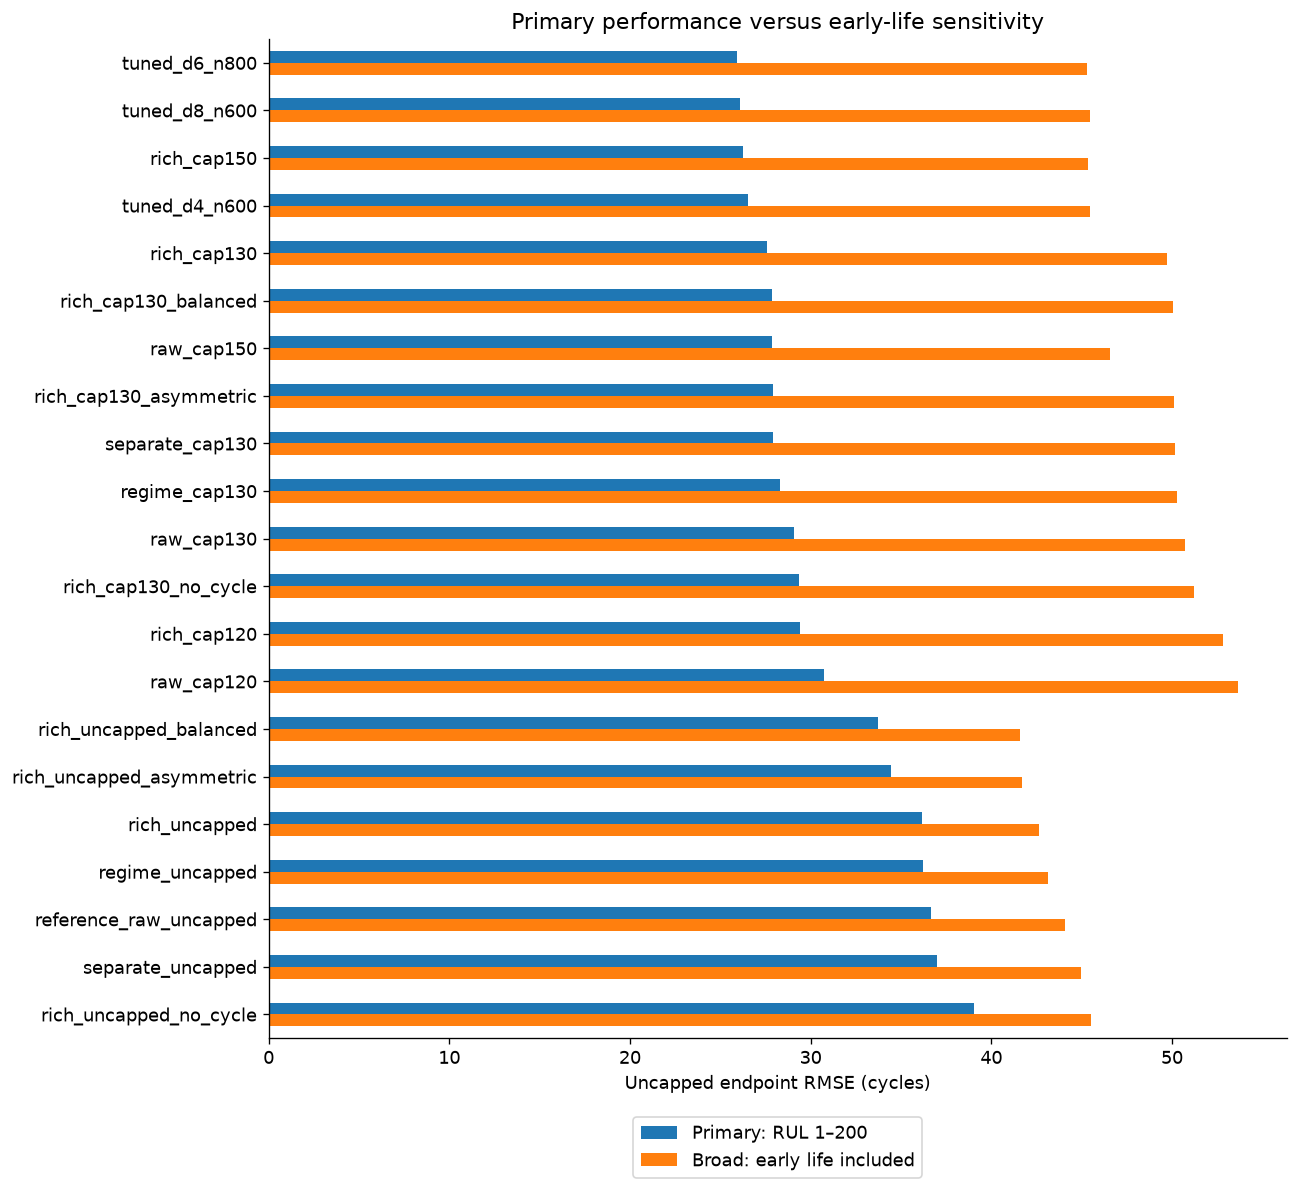

In [3]:
primary=comparison[comparison.protocol.eq('primary')].sort_values('RMSE')
broad=comparison[comparison.protocol.eq('broad')].set_index('candidate')
display(primary[['candidate','RMSE','MAE','bias','NASA_score_mean','recall']].round(3))
chart=primary.set_index('candidate')[['RMSE']].rename(columns={'RMSE':'Primary: RUL 1–200'})
chart['Broad: early life included']=broad.RMSE
ax=chart.plot.barh(figsize=(11,10))
ax.invert_yaxis()
ax.set(xlabel='Uncapped endpoint RMSE (cycles)',ylabel='',title='Primary performance versus early-life sensitivity')
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.07))
plt.tight_layout()
plt.show()

### The cost and benefit of capping targets

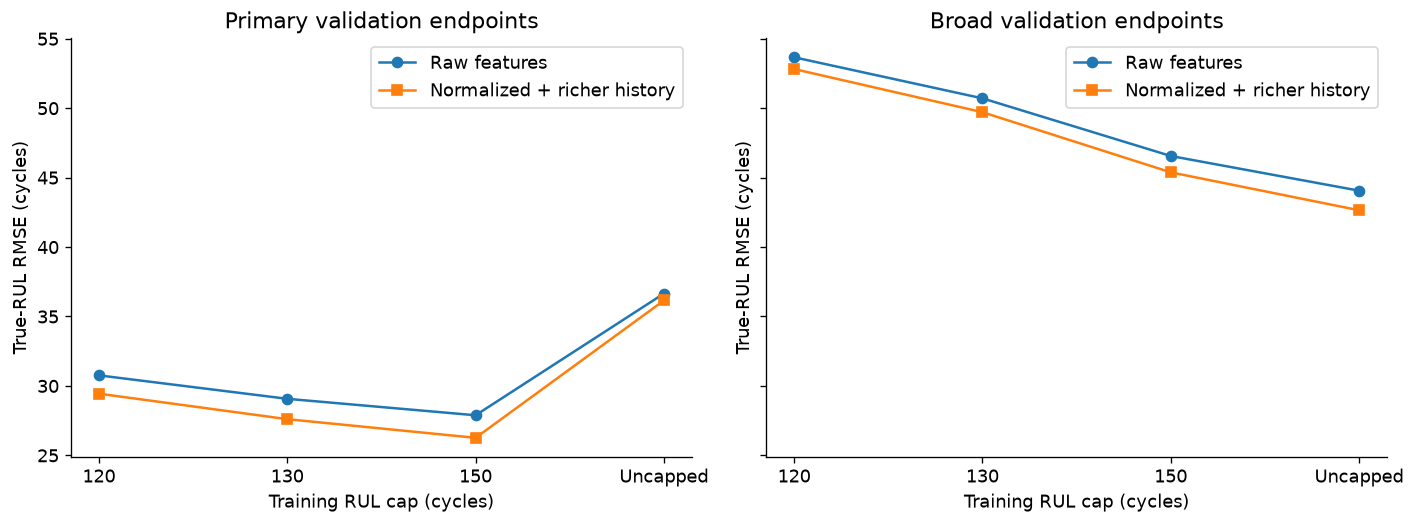

In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5),sharey=True)
for ax,protocol in zip(axes,['primary','broad']):
    table=comparison[comparison.protocol.eq(protocol)].set_index('candidate')
    for prefix,label,marker in [('raw','Raw features','o'),('rich','Normalized + richer history','s')]:
        names=[f'{prefix}_cap120',f'{prefix}_cap130',f'{prefix}_cap150',
               'reference_raw_uncapped' if prefix=='raw' else 'rich_uncapped']
        ax.plot(range(4),table.loc[names,'RMSE'],marker=marker,label=label)
    ax.set(xticks=range(4),xticklabels=['120','130','150','Uncapped'],xlabel='Training RUL cap (cycles)',
           ylabel='True-RUL RMSE (cycles)',title=protocol.capitalize()+' validation endpoints')
    ax.legend()
fig.tight_layout()
plt.show()

### Engine-age shortcut and feature reliance
Cycle removal is a controlled predictive test; feature importance alone cannot establish that a shortcut is harmful or prove a physical degradation mechanism. The chart below uses normalized tree gain from the selected configuration fitted on development engines. Correlated sensor/history features can share or hide importance; this is not a SHAP or causal analysis. Separate models, if selected, have separate importance scales.

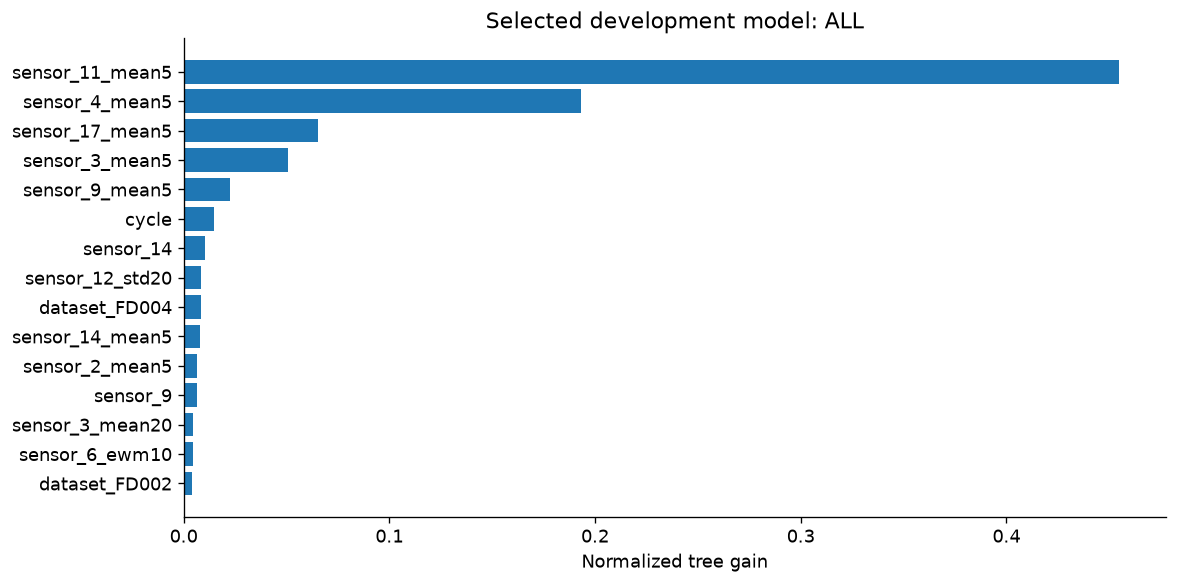

,candidate,RMSE,bias
15,rich_cap130,27.600,-5.852
21,rich_cap130_no_cycle,29.358,-5.444
25,rich_uncapped,36.147,11.440
31,rich_uncapped_no_cycle,39.050,13.238


In [5]:
importance=pd.read_csv(OUT/'feature_importance.csv')
scopes=importance.model_scope.unique()
fig,axes=plt.subplots(len(scopes),1,figsize=(10, max(5,4*len(scopes))),squeeze=False)
for ax,scope in zip(axes.flat,scopes):
    top=importance[importance.model_scope.eq(scope)].nlargest(15,'gain_importance').sort_values('gain_importance')
    ax.barh(top.feature,top.gain_importance)
    ax.set(title=f'Selected development model: {scope}',xlabel='Normalized tree gain',ylabel='')
fig.tight_layout()
plt.show()
no_cycle_names=['rich_uncapped','rich_uncapped_no_cycle','rich_cap130','rich_cap130_no_cycle']
display(primary[primary.candidate.isin(no_cycle_names)][['candidate','RMSE','bias']].round(3))

## 5. Untouched audit engines
Audit performance is evaluated after freezing model and threshold. The baseline is retrained using the same development engines as the selected model, making this a paired comparison. Bootstrap bounds resample whole audit engines to respect dependence among the three snapshots.

The interval describes uncertainty within this audit population and protocol; it is not a bound for real-world performance or the official test set. A positive RMSE-improvement value favors the selected model.

Paired audit-engine bootstrap: reference minus selected RMSE, 95% percentile interval [4.34, 10.59] cycles.


,model,protocol,RMSE,MAE,bias,NASA_score_mean,precision,recall
0,reference,primary,33.007,24.832,13.613,692.422,0.904,0.733
2,reference,broad,39.796,29.348,9.247,7311.697,0.980,0.662
4,selected,primary,25.675,18.830,-0.108,32.170,0.899,0.789
6,selected,broad,43.321,27.187,-9.073,271341.251,0.968,0.811


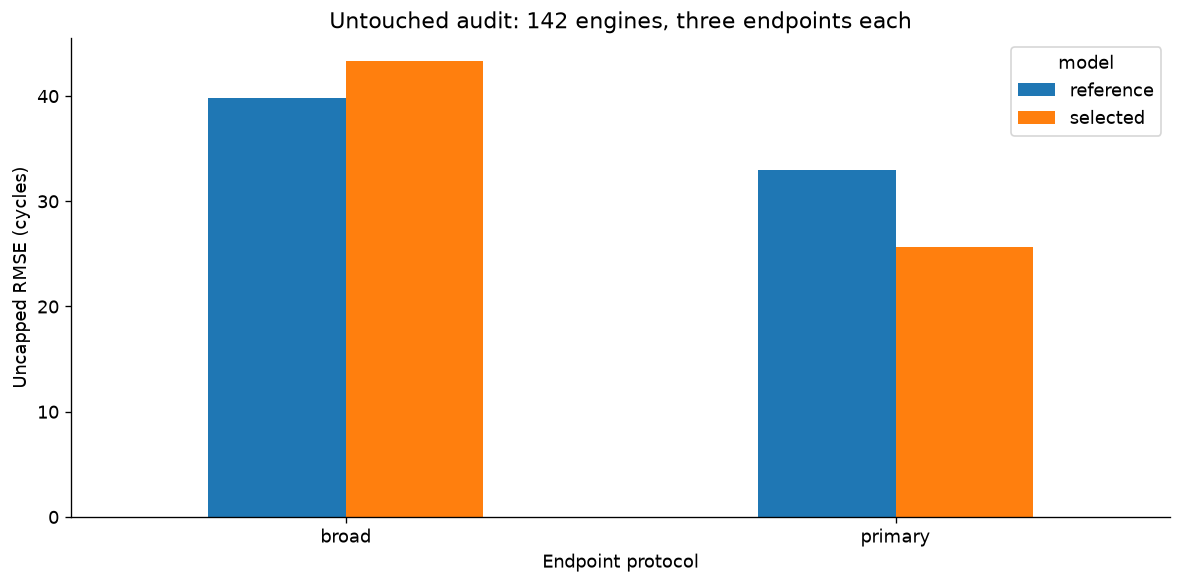

In [6]:
audit_fixed=audit_metrics[audit_metrics.threshold.eq(30)]
display(audit_fixed[['model','protocol','RMSE','MAE','bias','NASA_score_mean','precision','recall']].round(3))
ci=r['audit_bootstrap']
print(f"Paired audit-engine bootstrap: reference minus selected RMSE, 95% percentile interval [{ci['lower_95']:.2f}, {ci['upper_95']:.2f}] cycles.")
ax=audit_fixed.pivot(index='protocol',columns='model',values='RMSE').plot.bar(rot=0)
ax.set(title='Untouched audit: 142 engines, three endpoints each',ylabel='Uncapped RMSE (cycles)',xlabel='Endpoint protocol')
plt.tight_layout()
plt.show()

## 6. Maintenance threshold and asymmetric score
For error `d = prediction − true RUL`, the score is `sum(expm1(-d/13))` for negative errors plus `sum(expm1(d/10))` for nonnegative errors. Lower is better. This is the asymmetric score from [Saxena et al., equation 9](https://ntrs.nasa.gov/api/citations/20090029214/downloads/20090029214.pdf). Large errors can dominate it, so both sum and per-observation mean are retained. Sums over different populations/sample counts are not directly comparable.

The custom training loss multiplies squared-error gradients/Hessians by 1.5 for overestimation. Sample weights are explicitly applied, following the [XGBoost custom objective interface](https://xgboost.readthedocs.io/en/latest/python/python_api.html). Its gradients and Hessians were checked numerically before training. It is a candidate, not an automatically superior replacement for RMSE.

For the selected model, the smallest OOF threshold achieving ≥90% recall is frozen. Out-of-fold calibration shares data with model selection and can be optimistic; the untouched audit and test tables show how well it transfers. It changes the maintenance flag only, not the RUL prediction. The true event remains RUL ≤30 cycles. Refitting on all training engines can also shift calibration.

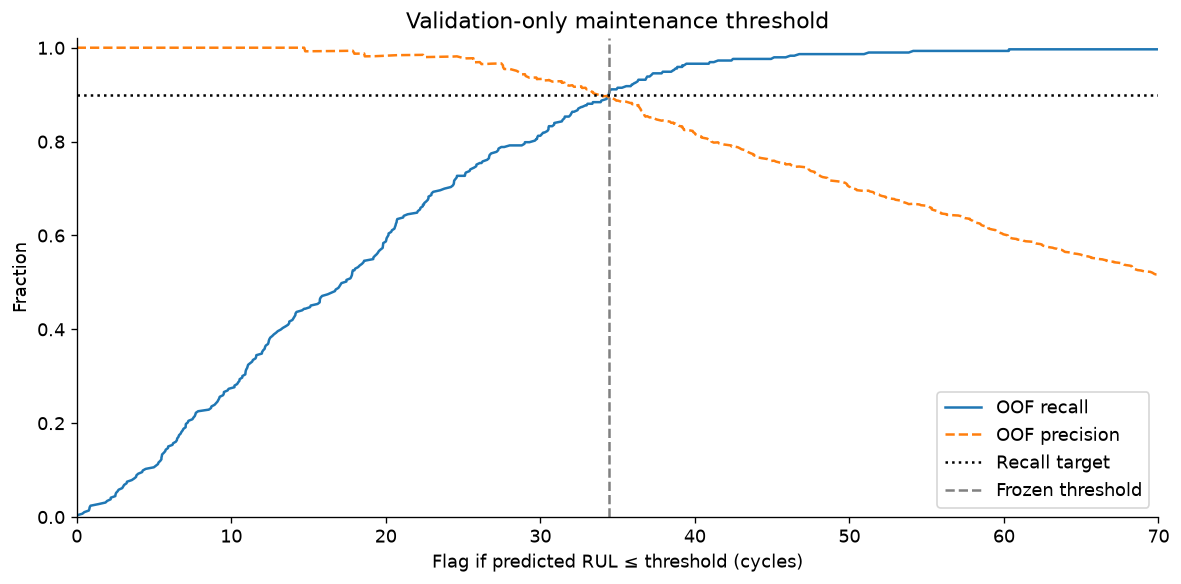

,threshold,precision,recall,TP,FP,FN,TN
4,30.000,0.899,0.789,71,8,19,328
5,34.438,0.890,0.900,81,10,9,326


In [7]:
curve=pd.read_csv(OUT/'threshold_curve.csv')
fig,ax=plt.subplots()
ax.plot(curve.threshold,curve.recall,label='OOF recall')
ax.plot(curve.threshold,curve.precision,linestyle='--',label='OOF precision')
ax.axhline(.9,color='black',linestyle=':',label='Recall target')
ax.axvline(r['alert_threshold'],color='gray',linestyle='--',label='Frozen threshold')
ax.set(xlim=(0, max(70,r['alert_threshold']+10)),ylim=(0,1.02),xlabel='Flag if predicted RUL ≤ threshold (cycles)',
       ylabel='Fraction',title='Validation-only maintenance threshold')
ax.legend(loc='lower right')
fig.tight_layout()
plt.show()
display(audit_metrics[(audit_metrics.model=='selected') & (audit_metrics.protocol=='primary')]
        [['threshold','precision','recall','TP','FP','FN','TN']].round(3))

## 7. Final official test — labels remain uncapped
The frozen model is refit on all 160,359 training rows, then evaluated on all 707 official endpoints. The old saved model predictions are rescored with the same formulas. A cap is applied only to training targets, never to actual validation/audit/test labels. Predictions are clipped below zero, with no imposed upper clip.

The previous official test has already influenced which experiments were proposed. The separate audit is useful evidence, but a fresh external dataset would be needed for a genuinely new external performance claim.

,model,n,RMSE,MAE,bias,NASA_score_sum,precision,recall
0,selected,707,22.634,16.229,0.313,1.211257e+04,0.947,0.899
10,Mean baseline,707,65.427,54.390,40.894,9.257715e+06,0.000,0.000
15,Random forest,707,33.143,23.261,11.942,4.181172e+06,0.942,0.824
20,Ridge,707,40.134,32.025,19.440,1.752869e+06,0.854,0.553
25,XGBoost,707,33.419,23.607,11.279,1.072132e+07,0.949,0.818


model,Mean baseline,Random forest,Ridge,XGBoost,selected
dataset,,,,,
ALL,65.427,33.143,40.134,33.419,22.634
FD001,62.595,25.063,32.829,24.275,17.837
FD002,67.714,27.713,30.775,28.194,24.474
FD003,62.639,39.542,53.641,40.115,18.275
FD004,65.215,38.023,44.811,38.305,23.914


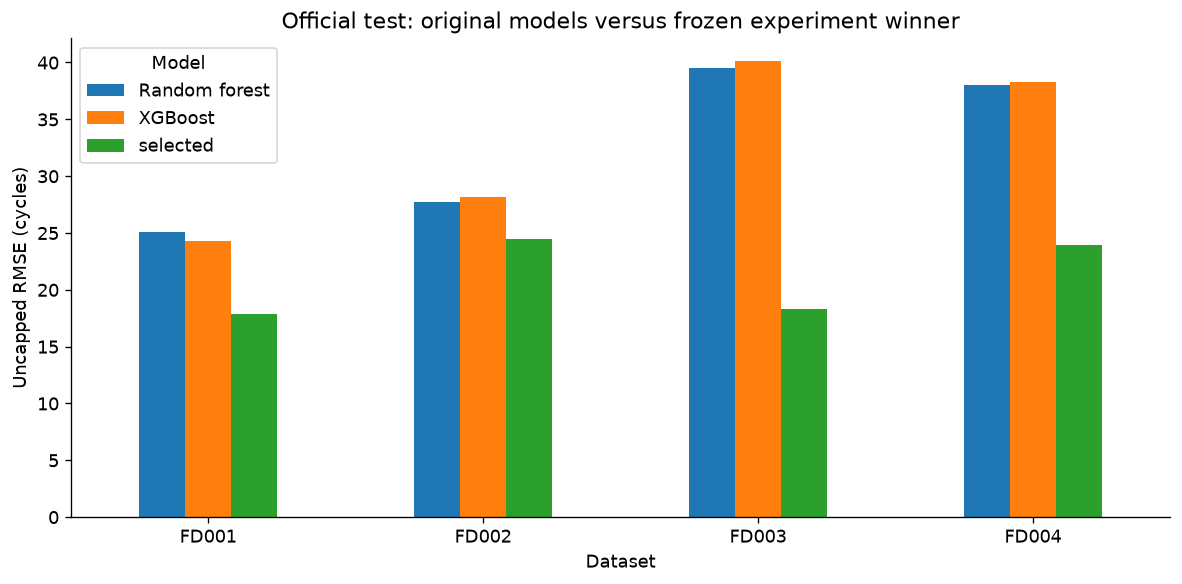

In [8]:
fixed=test_metrics[test_metrics.threshold.eq(30)]
display(fixed[fixed.dataset.eq('ALL')][['model','n','RMSE','MAE','bias','NASA_score_sum','precision','recall']].round(3))
display(fixed.pivot(index='dataset',columns='model',values='RMSE').round(3))
chart=fixed[fixed.dataset.ne('ALL') & fixed.model.isin(['Random forest','XGBoost','selected'])]
ax=chart.pivot(index='dataset',columns='model',values='RMSE').plot.bar(rot=0,figsize=(10,5))
ax.set(title='Official test: original models versus frozen experiment winner',xlabel='Dataset',ylabel='Uncapped RMSE (cycles)')
ax.legend(title='Model')
plt.tight_layout()
plt.show()

,threshold,precision,recall,TP,FP,FN,TN
0,30.000,0.947,0.899,143,8,16,540
1,34.438,0.925,0.937,149,12,10,536


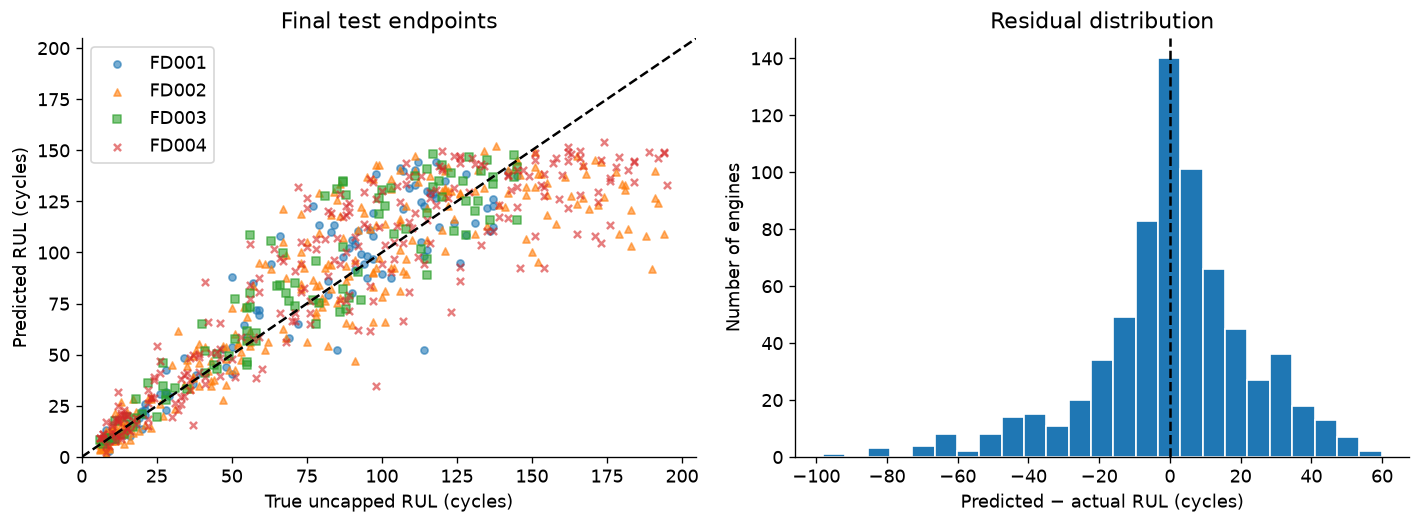

In [9]:
selected=test_metrics[test_metrics.model.eq('selected') & test_metrics.dataset.eq('ALL')]
display(selected[['threshold','precision','recall','TP','FP','FN','TN']].round(3))
pred=pd.read_csv(OUT/'test_predictions.csv')
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for dataset,marker in zip(['FD001','FD002','FD003','FD004'],['o','^','s','x']):
    p=pred[pred.dataset.eq(dataset)]
    axes[0].scatter(p.actual_RUL,p.predicted_RUL,s=18,marker=marker,label=dataset,alpha=.6)
limit=max(pred.actual_RUL.max(),pred.predicted_RUL.max())*1.05
axes[0].plot([0,limit],[0,limit],color='black',linestyle='--')
axes[0].set(xlim=(0,limit),ylim=(0,limit),xlabel='True uncapped RUL (cycles)',ylabel='Predicted RUL (cycles)',title='Final test endpoints')
axes[0].legend()
axes[1].hist(pred.predicted_RUL-pred.actual_RUL,bins=25,edgecolor='white')
axes[1].axvline(0,color='black',linestyle='--')
axes[1].set(xlabel='Predicted − actual RUL (cycles)',ylabel='Number of engines',title='Residual distribution')
fig.tight_layout()
plt.show()

## 8. Reuse and validation
Run the full experiment locally with `./nasa/bin/python scripts/run_experiments.py --threads 6`. The timestamped log, configuration matrix, fold membership, synthetic endpoints, all OOF predictions, frozen decision, audit predictions, bootstrap interval and official test predictions are under `outputs/experiments/`.

`selected_model.joblib` contains normalization, history feature construction, selectors and fitted model(s). Supply complete available histories with the same input schema; the implementation rejects unknown regimes. The original benchmark models remain under `outputs/all_engines/`.

Checks: raw baseline feature equivalence; future and target isolation; no cross-engine history; train-only regime statistics; unknown-regime rejection; numerical custom-loss derivatives; score signs; endpoint construction; engine separation; full serialized-model prediction equality. The regression/alert measurements remain educational benchmark results, not a safety or savings guarantee.

In [10]:
import joblib
train,test,_=load_inputs()
model=joblib.load(OUT/'selected_model.joblib')
engine=test[(test.dataset=='FD004') & (test.engine_id==1)]
value=float(model.predict(engine)[-1])
expected=pred[(pred.dataset=='FD004') & (pred.engine_id==1)].predicted_RUL.iloc[0]
assert np.isclose(value,expected)
print(f'Loaded model: FD004 engine 1 prediction {value:.2f} cycles; CSV match verified.')
print('Trained rows / engines:',model.training_rows_,model.training_engines_)

Loaded model: FD004 engine 1 prediction 26.45 cycles; CSV match verified.
Trained rows / engines: 160359 709
